# MobileNetV3-Large Diabetic Retinopathy Grading - Explainability

## 1. Setup

In [1]:
import sys, subprocess
for pkg in ["grad-cam", "lime", "scikit-image"]:
    try:
        __import__(pkg.replace("-", "_") if pkg != "grad-cam" else "pytorch_grad_cam")
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])


In [2]:
import os, json, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import timm
import matplotlib.pyplot as plt
import matplotlib.cm
from PIL import Image
from sklearn.metrics import (
    cohen_kappa_score, accuracy_score, f1_score, confusion_matrix, classification_report,
)
warnings.filterwarnings("ignore")


In [3]:
ROOT = Path("..").resolve()
DATA_ROOT = ROOT / "data" / "diabetic-retinopathy-detection"
TEST_DIR = DATA_ROOT / "test_labels_proc"
TEST_CSV = DATA_ROOT / "test_split.csv"
OUT = ROOT / "outputs" / "explainability"
OUT.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "mobilenetv3_large_100.ra_in1k"
IMAGE_SIZE = 224
NUM_CLASSES = 5
CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
MEAN = (0.5, 0.5, 0.5)
STD = (0.5, 0.5, 0.5)

CKPT_RUN6 = ROOT / "outputs" / "mobilenet_dr_training_exp6" / "checkpoints" / "mobilenet_dr_training_exp6_best.pt"
CKPT_RUN9 = ROOT / "outputs" / "mobilenet_dr_training_exp9" / "checkpoints" / "mobilenet_dr_training_exp9_best.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("test images:", len(list(TEST_DIR.glob("*.jpeg"))))


device: cpu
test images: 5269


In [4]:
test_transform = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.CenterCrop(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

display_transform = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.CenterCrop(IMAGE_SIZE),
])

def load_image(image_id):
    pil = Image.open(TEST_DIR / f"{image_id}.jpeg").convert("RGB")
    return display_transform(pil), test_transform(pil).unsqueeze(0)

def load_model(ckpt_path):
    model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    state = ckpt["model_state"] if isinstance(ckpt, dict) and "model_state" in ckpt else ckpt
    model.load_state_dict(state)
    model.eval()
    return model

model_run6 = load_model(CKPT_RUN6)
print("loaded Run 6")


loaded Run 6


In [5]:
from torch.utils.data import Dataset, DataLoader

class TestDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        pil = Image.open(TEST_DIR / f"{row['image']}.jpeg").convert("RGB")
        return test_transform(pil), int(row["level"]), row["image"]

test_df = pd.read_csv(TEST_CSV)
test_ds = TestDataset(test_df)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)

all_probs = []
all_preds = []
all_labels = []
all_ids = []

t0 = time.time() if False else __import__("time").time()
import time as _time
t_start = _time.time()
with torch.no_grad():
    for images, labels, ids in test_loader:
        images = images.to(device)
        logits = model_run6(images)
        probs = F.softmax(logits, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.tolist())
        all_ids.extend(list(ids))

all_probs = np.concatenate(all_probs, axis=0)
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_ids = np.array(all_ids)

print(f"forward pass: {_time.time() - t_start:.1f}s")
print(f"shape: probs={all_probs.shape}, preds={all_preds.shape}")
print(f"QWK: {cohen_kappa_score(all_labels, all_preds, weights='quadratic'):.4f}")
print(f"Accuracy: {accuracy_score(all_labels, all_preds):.4f}")
print(f"Macro F1: {f1_score(all_labels, all_preds, average='macro'):.4f}")


forward pass: 128.7s
shape: probs=(5269, 5), preds=(5269,)
QWK: 0.6338
Accuracy: 0.7785
Macro F1: 0.4695


## 2. Per-grade sample images

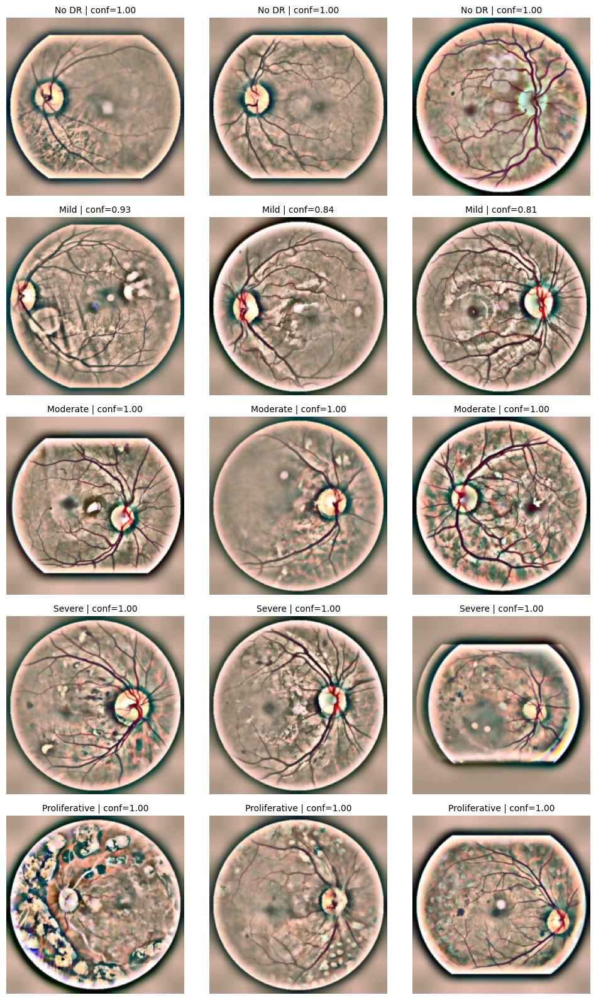

In [6]:
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(10, 16))
for grade in range(NUM_CLASSES):
    mask = (all_labels == grade) & (all_preds == grade)
    if mask.sum() == 0:
        for c in range(3):
            axes[grade, c].axis("off")
            axes[grade, c].set_title(f"{CLASS_NAMES[grade]} - no correct predictions", fontsize=9)
        continue
    confidences = all_probs[mask, grade]
    top_idx_in_mask = np.argsort(confidences)[::-1][:3]
    mask_indices = np.where(mask)[0]
    top_global_idx = mask_indices[top_idx_in_mask]
    for c, gidx in enumerate(top_global_idx):
        pil_disp, _ = load_image(all_ids[gidx])
        axes[grade, c].imshow(np.array(pil_disp))
        axes[grade, c].axis("off")
        axes[grade, c].set_title(f"{CLASS_NAMES[grade]} | conf={all_probs[gidx, grade]:.2f}", fontsize=10)
    for c in range(len(top_global_idx), 3):
        axes[grade, c].axis("off")

plt.tight_layout()
plt.savefig(OUT / "fig01_per_grade_samples.png", dpi=110, bbox_inches="tight")
plt.show()


## 3. Grad-CAM++

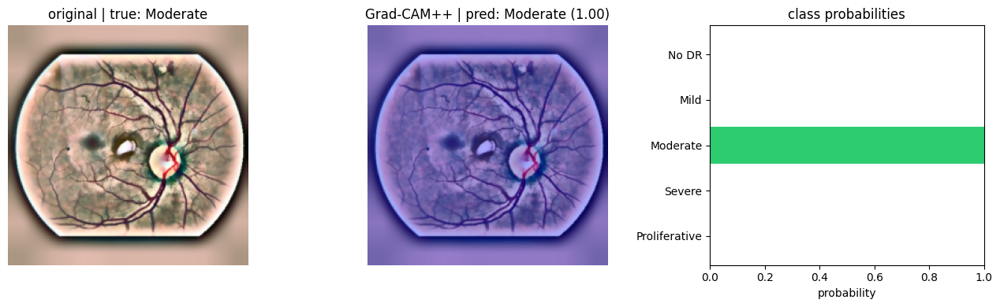

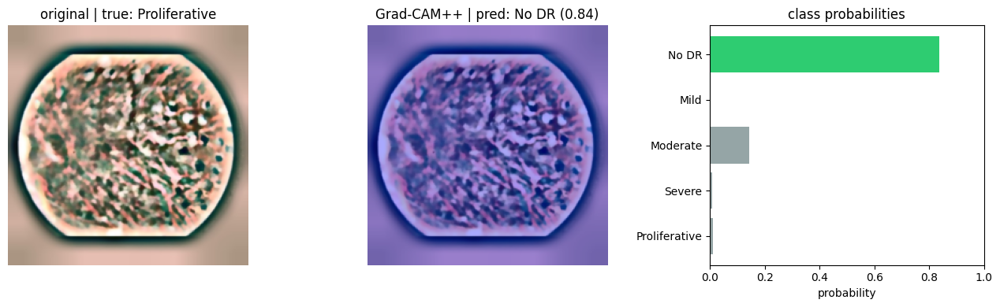

In [7]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image

target_layer = model_run6.conv_head
cam_gradcam = GradCAMPlusPlus(model=model_run6, target_layers=[target_layer])

def gradcam_triptych(image_id, true_label, save_name):
    pil_disp, tensor = load_image(image_id)
    tensor = tensor.to(device)
    with torch.no_grad():
        probs = F.softmax(model_run6(tensor), dim=1).squeeze().cpu().numpy()
    pred = int(probs.argmax())
    cam_output = cam_gradcam(input_tensor=tensor, targets=None)[0]

    img_norm = np.array(pil_disp).astype(np.float32) / 255.0
    overlay = show_cam_on_image(img_norm, cam_output, use_rgb=True)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(img_norm)
    axes[0].axis("off")
    axes[0].set_title(f"original | true: {CLASS_NAMES[true_label]}")

    axes[1].imshow(overlay)
    axes[1].axis("off")
    axes[1].set_title(f"Grad-CAM++ | pred: {CLASS_NAMES[pred]} ({probs[pred]:.2f})")

    axes[2].barh(range(NUM_CLASSES), probs, color=["#2ecc71" if i == pred else "#95a5a6" for i in range(NUM_CLASSES)])
    axes[2].set_yticks(range(NUM_CLASSES))
    axes[2].set_yticklabels(CLASS_NAMES)
    axes[2].invert_yaxis()
    axes[2].set_xlim(0, 1)
    axes[2].set_xlabel("probability")
    axes[2].set_title("class probabilities")

    plt.tight_layout()
    plt.savefig(OUT / save_name, dpi=110, bbox_inches="tight")
    plt.show()
    return pred, probs

correct_grade2 = np.where((all_labels == 2) & (all_preds == 2))[0]
wrong_any = np.where(all_labels != all_preds)[0]

if len(correct_grade2) > 0:
    idx = correct_grade2[np.argmax(all_probs[correct_grade2, 2])]
    gradcam_triptych(all_ids[idx], int(all_labels[idx]), "fig02_gradcam_correct.png")

if len(wrong_any) > 0:
    idx = wrong_any[np.argmax(np.abs(all_preds[wrong_any] - all_labels[wrong_any]))]
    gradcam_triptych(all_ids[idx], int(all_labels[idx]), "fig03_gradcam_wrong.png")


## 4. Per-grade Grad-CAM++ gallery

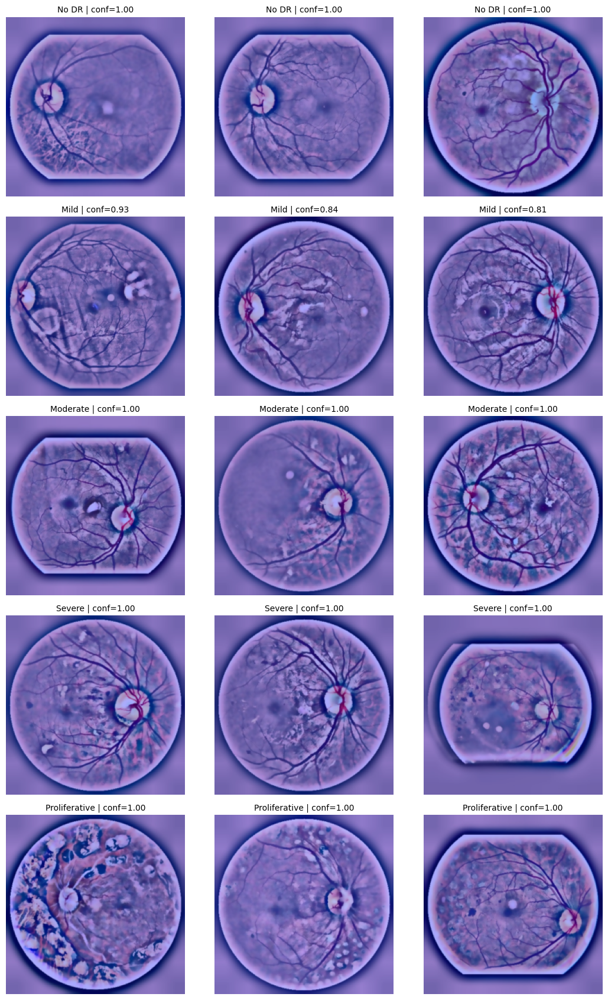

In [8]:
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(11, 17))
for grade in range(NUM_CLASSES):
    mask = (all_labels == grade) & (all_preds == grade)
    if mask.sum() == 0:
        for c in range(3):
            axes[grade, c].axis("off")
        continue
    confidences = all_probs[mask, grade]
    top_idx_in_mask = np.argsort(confidences)[::-1][:3]
    mask_indices = np.where(mask)[0]
    top_global_idx = mask_indices[top_idx_in_mask]

    for c, gidx in enumerate(top_global_idx):
        pil_disp, tensor = load_image(all_ids[gidx])
        tensor = tensor.to(device)
        cam_output = cam_gradcam(input_tensor=tensor, targets=None)[0]
        img_norm = np.array(pil_disp).astype(np.float32) / 255.0
        overlay = show_cam_on_image(img_norm, cam_output, use_rgb=True)
        axes[grade, c].imshow(overlay)
        axes[grade, c].axis("off")
        axes[grade, c].set_title(f"{CLASS_NAMES[grade]} | conf={all_probs[gidx, grade]:.2f}", fontsize=10)
    for c in range(len(top_global_idx), 3):
        axes[grade, c].axis("off")

plt.tight_layout()
plt.savefig(OUT / "fig04_gradcam_gallery.png", dpi=110, bbox_inches="tight")
plt.show()


## 5. Score-CAM

  0%|          | 0/80 [00:00<?, ?it/s]

  1%|▏         | 1/80 [00:00<00:19,  4.14it/s]

  2%|▎         | 2/80 [00:00<00:16,  4.61it/s]

  4%|▍         | 3/80 [00:00<00:16,  4.75it/s]

  5%|▌         | 4/80 [00:00<00:15,  4.87it/s]

...

 96%|█████████▋| 77/80 [00:15<00:00,  4.82it/s]

 98%|█████████▊| 78/80 [00:16<00:00,  4.54it/s]

 99%|█████████▉| 79/80 [00:16<00:00,  4.38it/s]

100%|██████████| 80/80 [00:16<00:00,  4.37it/s]

100%|██████████| 80/80 [00:16<00:00,  4.81it/s]

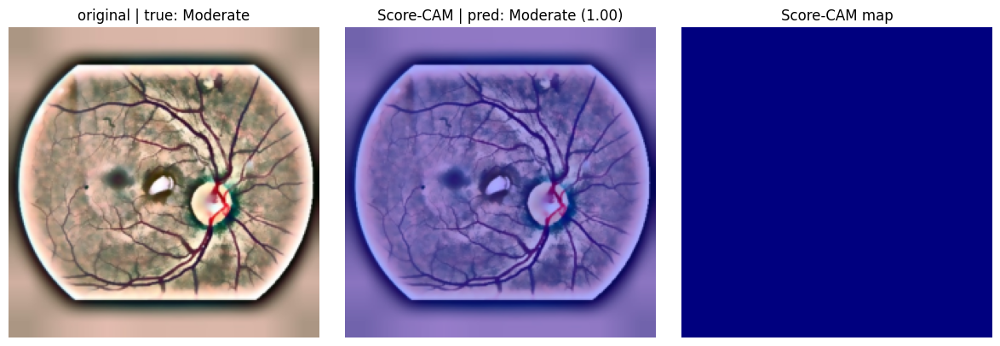

In [9]:
from pytorch_grad_cam import ScoreCAM

cam_score = ScoreCAM(model=model_run6, target_layers=[target_layer])

def scorecam_triptych(image_id, true_label, save_name):
    pil_disp, tensor = load_image(image_id)
    tensor = tensor.to(device)
    with torch.no_grad():
        probs = F.softmax(model_run6(tensor), dim=1).squeeze().cpu().numpy()
    pred = int(probs.argmax())
    cam_output = cam_score(input_tensor=tensor, targets=None)[0]

    img_norm = np.array(pil_disp).astype(np.float32) / 255.0
    overlay = show_cam_on_image(img_norm, cam_output, use_rgb=True)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img_norm)
    axes[0].axis("off")
    axes[0].set_title(f"original | true: {CLASS_NAMES[true_label]}")
    axes[1].imshow(overlay)
    axes[1].axis("off")
    axes[1].set_title(f"Score-CAM | pred: {CLASS_NAMES[pred]} ({probs[pred]:.2f})")
    axes[2].imshow(cam_output, cmap="jet")
    axes[2].axis("off")
    axes[2].set_title("Score-CAM map")
    plt.tight_layout()
    plt.savefig(OUT / save_name, dpi=110, bbox_inches="tight")
    plt.show()

if len(correct_grade2) > 0:
    idx = correct_grade2[np.argmax(all_probs[correct_grade2, 2])]
    scorecam_triptych(all_ids[idx], int(all_labels[idx]), "fig05_scorecam.png")


## 6. Integrated Gradients

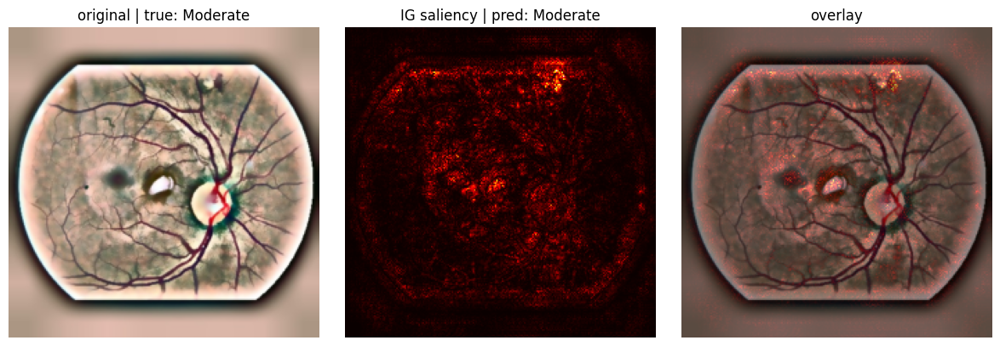

In [10]:
def integrated_gradients(model, input_tensor, target_class, steps=32):
    baseline = torch.zeros_like(input_tensor).to(device)
    alphas = torch.linspace(0, 1, steps).to(device)
    grads = []
    for a in alphas:
        x = baseline + a * (input_tensor - baseline)
        x.requires_grad_(True)
        model.zero_grad()
        logits = model(x)
        score = logits[0, target_class]
        score.backward()
        grads.append(x.grad.detach().clone())
    avg_grad = torch.stack(grads).mean(dim=0)
    ig = (input_tensor - baseline) * avg_grad
    return ig.squeeze().cpu().numpy()

def ig_panel(image_id, true_label, save_name):
    pil_disp, tensor = load_image(image_id)
    tensor = tensor.to(device)
    with torch.no_grad():
        probs = F.softmax(model_run6(tensor), dim=1).squeeze().cpu().numpy()
    pred = int(probs.argmax())
    ig_map = integrated_gradients(model_run6, tensor, pred, steps=24)
    saliency = np.abs(ig_map).sum(axis=0)
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

    img_norm = np.array(pil_disp).astype(np.float32) / 255.0
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img_norm)
    axes[0].axis("off")
    axes[0].set_title(f"original | true: {CLASS_NAMES[true_label]}")
    axes[1].imshow(saliency, cmap="hot")
    axes[1].axis("off")
    axes[1].set_title(f"IG saliency | pred: {CLASS_NAMES[pred]}")
    overlay = 0.5 * img_norm + 0.5 * matplotlib.cm.hot(saliency)[..., :3]
    axes[2].imshow(np.clip(overlay, 0, 1))
    axes[2].axis("off")
    axes[2].set_title("overlay")
    plt.tight_layout()
    plt.savefig(OUT / save_name, dpi=110, bbox_inches="tight")
    plt.show()

if len(correct_grade2) > 0:
    idx = correct_grade2[np.argmax(all_probs[correct_grade2, 2])]
    ig_panel(all_ids[idx], int(all_labels[idx]), "fig06_integrated_gradients.png")


## 7. SmoothGrad

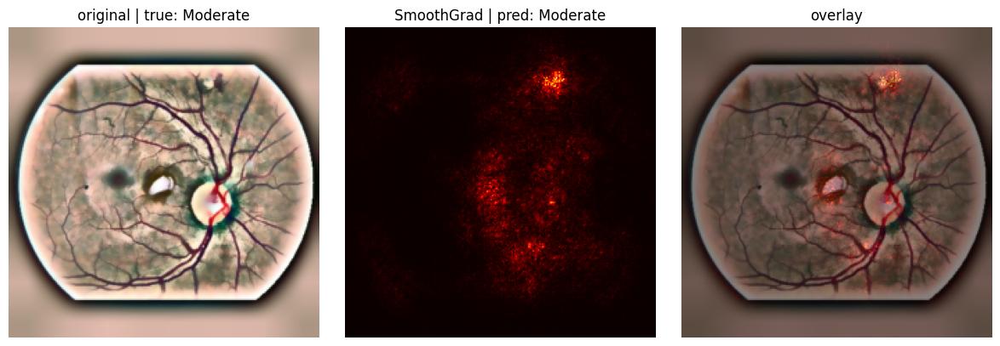

In [11]:
def smoothgrad(model, input_tensor, target_class, n_samples=16, noise_sigma=0.15):
    grads = []
    for _ in range(n_samples):
        noise = torch.randn_like(input_tensor) * noise_sigma
        x = (input_tensor + noise).to(device)
        x.requires_grad_(True)
        model.zero_grad()
        logits = model(x)
        score = logits[0, target_class]
        score.backward()
        grads.append(x.grad.detach().clone())
    avg = torch.stack(grads).mean(dim=0)
    return avg.squeeze().cpu().numpy()

def sg_panel(image_id, true_label, save_name):
    pil_disp, tensor = load_image(image_id)
    tensor = tensor.to(device)
    with torch.no_grad():
        probs = F.softmax(model_run6(tensor), dim=1).squeeze().cpu().numpy()
    pred = int(probs.argmax())
    sg_map = smoothgrad(model_run6, tensor, pred, n_samples=12, noise_sigma=0.15)
    saliency = np.abs(sg_map).sum(axis=0)
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

    img_norm = np.array(pil_disp).astype(np.float32) / 255.0
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img_norm)
    axes[0].axis("off")
    axes[0].set_title(f"original | true: {CLASS_NAMES[true_label]}")
    axes[1].imshow(saliency, cmap="hot")
    axes[1].axis("off")
    axes[1].set_title(f"SmoothGrad | pred: {CLASS_NAMES[pred]}")
    overlay = 0.5 * img_norm + 0.5 * matplotlib.cm.hot(saliency)[..., :3]
    axes[2].imshow(np.clip(overlay, 0, 1))
    axes[2].axis("off")
    axes[2].set_title("overlay")
    plt.tight_layout()
    plt.savefig(OUT / save_name, dpi=110, bbox_inches="tight")
    plt.show()

if len(correct_grade2) > 0:
    idx = correct_grade2[np.argmax(all_probs[correct_grade2, 2])]
    sg_panel(all_ids[idx], int(all_labels[idx]), "fig07_smoothgrad.png")


## 8. Grade 1 false negatives - Run 6 vs Run 9

Grade 1 misclassified as Grade 0: 303 cases
loaded Run 9


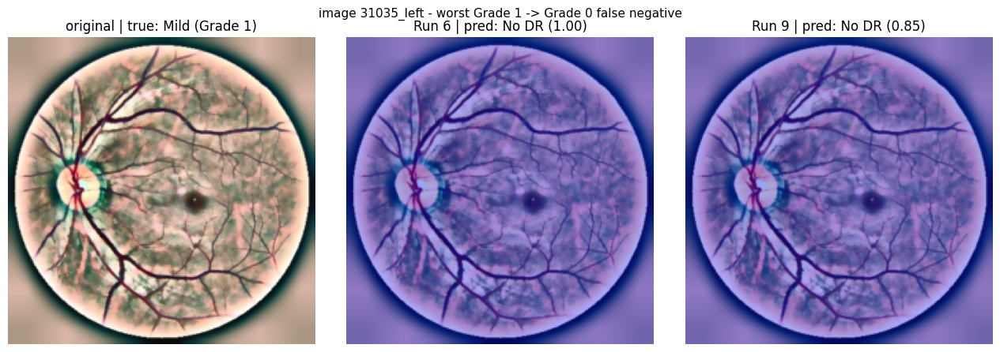

image_id: 31035_left
Run 6 probs: {'No DR': np.float32(1.0), 'Mild': np.float32(0.0), 'Moderate': np.float32(0.0), 'Severe': np.float32(0.0), 'Proliferative': np.float32(0.0)}
Run 9 probs: {'No DR': np.float32(0.848), 'Mild': np.float32(0.142), 'Moderate': np.float32(0.007), 'Severe': np.float32(0.003), 'Proliferative': np.float32(0.0)}


In [12]:
fn_mask = (all_labels == 1) & (all_preds == 0)
print(f"Grade 1 misclassified as Grade 0: {fn_mask.sum()} cases")

model_run9 = load_model(CKPT_RUN9)
print("loaded Run 9")

cam_run6 = GradCAMPlusPlus(model=model_run6, target_layers=[model_run6.conv_head])
cam_run9 = GradCAMPlusPlus(model=model_run9, target_layers=[model_run9.conv_head])

if fn_mask.sum() > 0:
    fn_indices = np.where(fn_mask)[0]
    conf_grade0 = all_probs[fn_indices, 0]
    worst_idx = fn_indices[np.argmax(conf_grade0)]
    img_id = all_ids[worst_idx]

    pil_disp, tensor = load_image(img_id)
    tensor = tensor.to(device)

    with torch.no_grad():
        probs_6 = F.softmax(model_run6(tensor), dim=1).squeeze().cpu().numpy()
        probs_9 = F.softmax(model_run9(tensor), dim=1).squeeze().cpu().numpy()
    pred_6 = int(probs_6.argmax())
    pred_9 = int(probs_9.argmax())

    cam_6 = cam_run6(input_tensor=tensor, targets=None)[0]
    cam_9 = cam_run9(input_tensor=tensor, targets=None)[0]

    img_norm = np.array(pil_disp).astype(np.float32) / 255.0
    overlay_6 = show_cam_on_image(img_norm, cam_6, use_rgb=True)
    overlay_9 = show_cam_on_image(img_norm, cam_9, use_rgb=True)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
    axes[0].imshow(img_norm)
    axes[0].axis("off")
    axes[0].set_title(f"original | true: {CLASS_NAMES[1]} (Grade 1)")
    axes[1].imshow(overlay_6)
    axes[1].axis("off")
    axes[1].set_title(f"Run 6 | pred: {CLASS_NAMES[pred_6]} ({probs_6[pred_6]:.2f})")
    axes[2].imshow(overlay_9)
    axes[2].axis("off")
    axes[2].set_title(f"Run 9 | pred: {CLASS_NAMES[pred_9]} ({probs_9[pred_9]:.2f})")
    fig.suptitle(f"image {img_id} - worst Grade 1 -> Grade 0 false negative", fontsize=11)
    plt.tight_layout()
    plt.savefig(OUT / "fig08_grade1_false_negative_run6_vs_run9.png", dpi=120, bbox_inches="tight")
    plt.show()

    print(f"image_id: {img_id}")
    print(f"Run 6 probs: {dict(zip(CLASS_NAMES, np.round(probs_6, 3)))}")
    print(f"Run 9 probs: {dict(zip(CLASS_NAMES, np.round(probs_9, 3)))}")


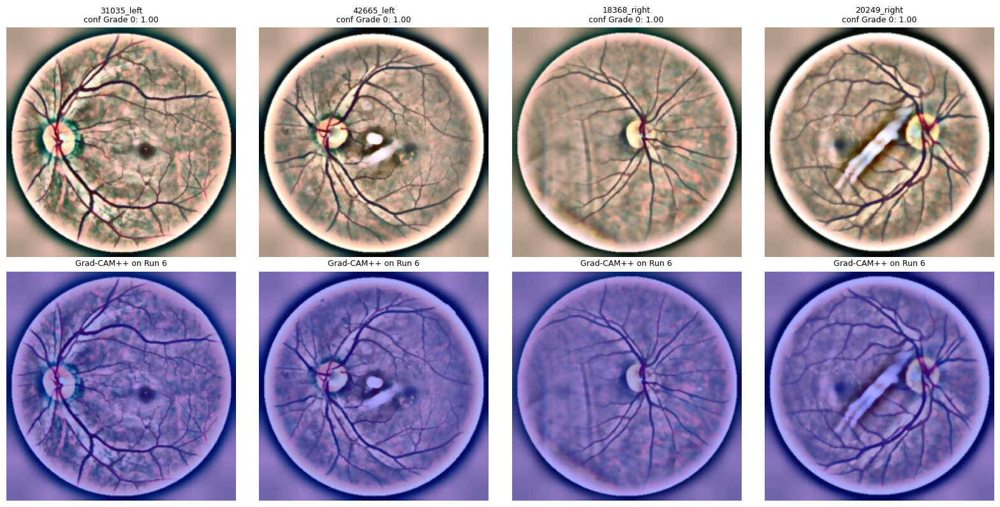

In [13]:
if fn_mask.sum() > 0:
    fn_indices = np.where(fn_mask)[0]
    conf_grade0 = all_probs[fn_indices, 0]
    top_n = min(4, len(fn_indices))
    worst_n = fn_indices[np.argsort(conf_grade0)[::-1][:top_n]]

    fig, axes = plt.subplots(2, top_n, figsize=(4 * top_n, 8))
    if top_n == 1:
        axes = axes.reshape(2, 1)

    for c, gidx in enumerate(worst_n):
        pil_disp, tensor = load_image(all_ids[gidx])
        tensor = tensor.to(device)
        cam_out = cam_run6(input_tensor=tensor, targets=None)[0]
        img_norm = np.array(pil_disp).astype(np.float32) / 255.0
        overlay = show_cam_on_image(img_norm, cam_out, use_rgb=True)

        axes[0, c].imshow(img_norm)
        axes[0, c].axis("off")
        axes[0, c].set_title(f"{all_ids[gidx]}\nconf Grade 0: {all_probs[gidx, 0]:.2f}", fontsize=9)
        axes[1, c].imshow(overlay)
        axes[1, c].axis("off")
        axes[1, c].set_title("Grad-CAM++ on Run 6", fontsize=9)

    plt.tight_layout()
    plt.savefig(OUT / "fig09_grade1_fn_gallery.png", dpi=110, bbox_inches="tight")
    plt.show()


## 9. Misclassification analysis

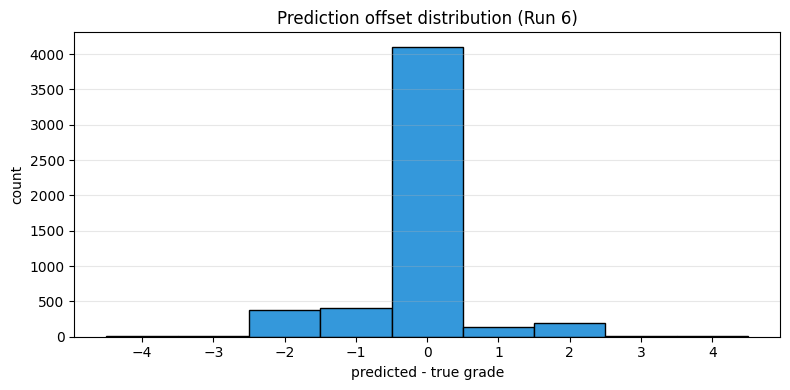

correct: 4102 (77.9%)
off by 1: 545 (10.3%)
off by 2+: 622 (11.8%)


In [14]:
offsets = all_preds - all_labels
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(-4.5, 5.5, 1)
ax.hist(offsets, bins=bins, color="#3498db", edgecolor="black")
ax.set_xlabel("predicted - true grade")
ax.set_ylabel("count")
ax.set_title(f"Prediction offset distribution (Run 6)")
ax.set_xticks(range(-4, 5))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "fig10_offset_hist.png", dpi=110, bbox_inches="tight")
plt.show()

print(f"correct: {(offsets == 0).sum()} ({(offsets == 0).mean()*100:.1f}%)")
print(f"off by 1: {(np.abs(offsets) == 1).sum()} ({(np.abs(offsets) == 1).mean()*100:.1f}%)")
print(f"off by 2+: {(np.abs(offsets) >= 2).sum()} ({(np.abs(offsets) >= 2).mean()*100:.1f}%)")


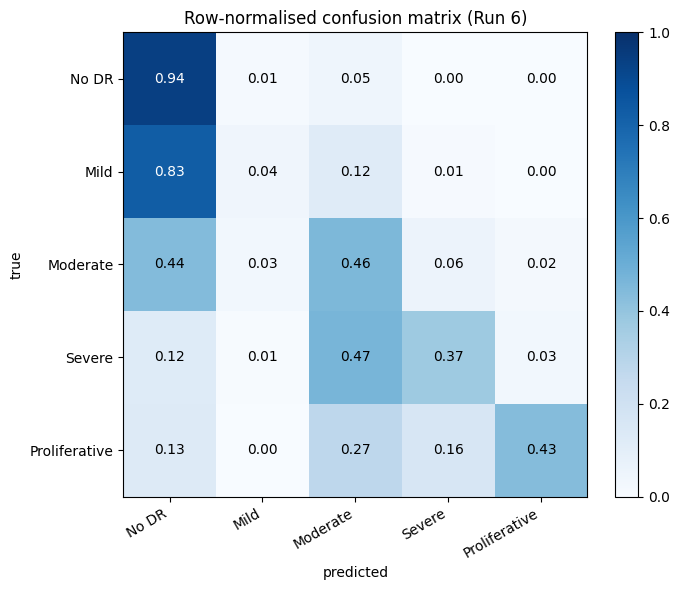

In [15]:
cm = confusion_matrix(all_labels, all_preds, labels=list(range(NUM_CLASSES)))
row_sums = cm.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
cm_norm = cm / row_sums

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Row-normalised confusion matrix (Run 6)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_norm[i,j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i,j] > 0.5 else "black", fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(OUT / "fig11_confusion_normalised.png", dpi=110, bbox_inches="tight")
plt.show()


severe errors (|offset| >= 2): 622


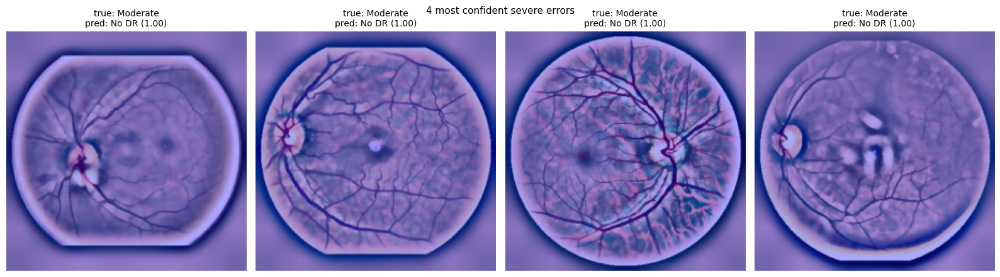

In [16]:
severe_errors = np.where(np.abs(offsets) >= 2)[0]
print(f"severe errors (|offset| >= 2): {len(severe_errors)}")

if len(severe_errors) > 0:
    confidences = all_probs[severe_errors, all_preds[severe_errors]]
    top4 = severe_errors[np.argsort(confidences)[::-1][:4]]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
    for c, gidx in enumerate(top4):
        pil_disp, tensor = load_image(all_ids[gidx])
        tensor = tensor.to(device)
        cam_out = cam_run6(input_tensor=tensor, targets=None)[0]
        img_norm = np.array(pil_disp).astype(np.float32) / 255.0
        overlay = show_cam_on_image(img_norm, cam_out, use_rgb=True)
        axes[c].imshow(overlay)
        axes[c].axis("off")
        axes[c].set_title(
            f"true: {CLASS_NAMES[all_labels[gidx]]}\n"
            f"pred: {CLASS_NAMES[all_preds[gidx]]} ({all_probs[gidx, all_preds[gidx]]:.2f})",
            fontsize=10,
        )
    fig.suptitle("4 most confident severe errors", fontsize=11)
    plt.tight_layout()
    plt.savefig(OUT / "fig12_severe_errors.png", dpi=110, bbox_inches="tight")
    plt.show()


## 10. Confidence calibration

Expected Calibration Error (Run 6): 0.1601


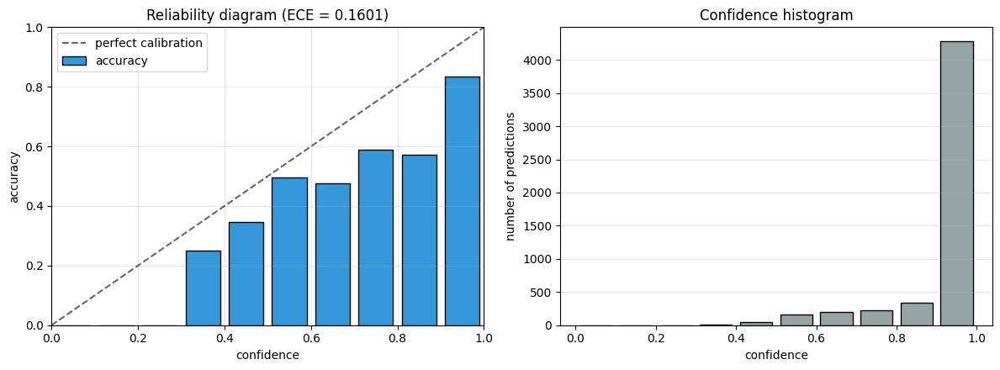

In [17]:
def expected_calibration_error(probs, labels, n_bins=10):
    preds = probs.argmax(axis=1)
    confidences = probs.max(axis=1)
    correct = (preds == labels).astype(float)
    ece = 0.0
    n = len(labels)
    bin_edges = np.linspace(0, 1, n_bins + 1)
    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        mask = (confidences >= lo) & (confidences < hi if i < n_bins - 1 else confidences <= hi)
        if mask.sum() == 0:
            continue
        acc_in_bin = correct[mask].mean()
        conf_in_bin = confidences[mask].mean()
        ece += (mask.sum() / n) * abs(acc_in_bin - conf_in_bin)
    return ece

ece = expected_calibration_error(all_probs, all_labels)
print(f"Expected Calibration Error (Run 6): {ece:.4f}")

n_bins = 10
bin_edges = np.linspace(0, 1, n_bins + 1)
preds = all_probs.argmax(axis=1)
confidences = all_probs.max(axis=1)
correct = (preds == all_labels).astype(float)

acc_per_bin = []
conf_per_bin = []
count_per_bin = []
for i in range(n_bins):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    mask = (confidences >= lo) & (confidences < hi if i < n_bins - 1 else confidences <= hi)
    if mask.sum() == 0:
        acc_per_bin.append(0)
        conf_per_bin.append((lo + hi) / 2)
    else:
        acc_per_bin.append(correct[mask].mean())
        conf_per_bin.append(confidences[mask].mean())
    count_per_bin.append(mask.sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(np.arange(n_bins) / n_bins + 0.05, acc_per_bin, width=0.08, color="#3498db", edgecolor="black", label="accuracy")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.6, label="perfect calibration")
axes[0].set_xlabel("confidence")
axes[0].set_ylabel("accuracy")
axes[0].set_title(f"Reliability diagram (ECE = {ece:.4f})")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(np.arange(n_bins) / n_bins + 0.05, count_per_bin, width=0.08, color="#95a5a6", edgecolor="black")
axes[1].set_xlabel("confidence")
axes[1].set_ylabel("number of predictions")
axes[1].set_title("Confidence histogram")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / "fig13_calibration.png", dpi=110, bbox_inches="tight")
plt.show()


## 11. Summary

In [ ]:
best_qwk = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
best_acc = accuracy_score(all_labels, all_preds)
best_f1 = f1_score(all_labels, all_preds, average='macro')
sev_err = (np.abs(all_preds - all_labels) >= 2).mean() * 100

print(f"Run 6 (best) final metrics on test set:")
print(f"  QWK      = {best_qwk:.4f}")
print(f"  Accuracy = {best_acc:.4f}")
print(f"  Macro F1 = {best_f1:.4f}")
print(f"  ECE      = {ece:.4f}")
print(f"  severe error rate = {sev_err:.1f}%")


Run 6 (best) final metrics on test set:
  QWK      = 0.6338
  Accuracy = 0.7785
  Macro F1 = 0.4695
  ECE      = 0.1601
  severe error rate = 11.8%
